In [112]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

In [113]:
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.size": 16
    }
)

In [114]:
fname_data = "./experiment_results.csv"
df = pd.read_csv(fname_data)
df.head()

,id,seq,dist_azo,activity_37,activity_60,wt_id,region
0,MARTIN_wt_2_mut_lowDCA_lowSB_beta1.25_sb-3.00_...,GUGCAUUCCGUCGGGAAACCACCGAAUGGCUGUUGUCAAAUUCGGU...,28,-2.982426,-3.578521,2.0,lowDCA_lowSB
1,MARTIN_wt_2_mut_lowDCA_lowSB_beta1.25_sb-3.00_696,GUGCAUUCCGUCGGGAAACCACCGAAUGGAUGUUGUCAAAUUCGGU...,25,-2.646676,-3.208042,2.0,lowDCA_lowSB
2,MARTIN_wt_2_mut_lowDCA_lowSB_beta1.25_sb-3.00_910,GUGCAUUCCGCCGGGAAACCACUGAAUGGCUGUUGUCAAAUUCGGU...,27,-0.592556,-2.084677,2.0,lowDCA_lowSB
3,MARTIN_wt_2_mut_lowDCA_lowSB_beta1.25_sb-3.00_545,GUGCAUUCCGUCGGGAAACCACCGAAUGGCUGUUGUCAAAUUCGGU...,29,-2.463253,-3.154773,2.0,lowDCA_lowSB
4,MARTIN_wt_2_mut_lowDCA_lowSB_beta1.25_sb-3.00_...,GUGCAUUUCGUCGGGAAACCACCGAAUGGCUGUUGUCAAAUUCGGU...,25,-1.349940,-2.098292,2.0,lowDCA_lowSB


## Calibration

In [116]:
df_control = df[df["region"] == "control"]
print(len(df_control))

# Retain only rows where both activity_37 and activity_60 are > -4.5
mask_1 = df_control["activity_37"] > -4.5
mask_2 = df_control["activity_60"] > -4.5
df_control_f = df_control[mask_1 & mask_2]
print(len(df_control_f))

1000
184


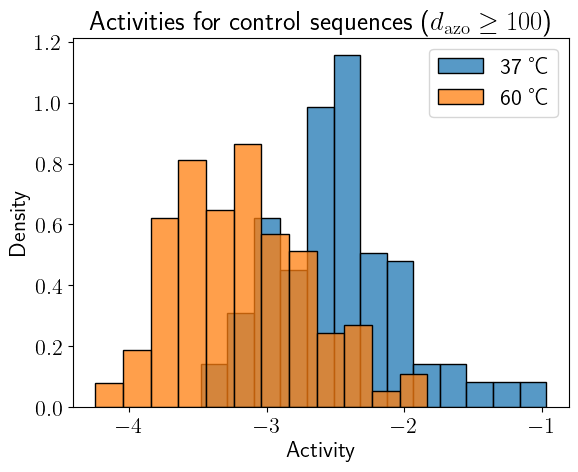

In [117]:
fig = plt.figure(dpi=100)
sns.histplot(
    df_control_f,
    x="activity_37",
    stat="density",
    binwidth=0.2,
)
sns.histplot(
    df_control_f,
    x="activity_60",
    stat="density",
    binwidth=0.2,
)
plt.title(r"Activities for control sequences ($d_{\mathrm{azo}} \geq 100$)")
plt.xlabel("Activity")
plt.legend(labels=["37 ℃", "60 ℃"])
plt.show()

In [122]:
# slope, intercept, r_value, p_value, std_err = stats.linregress(df_control_f["activity_37"], df_control_f["activity_60"])
# print("Slope:", slope)
# print("Intercept:", intercept)
# print("r_value:", r_value)
# print("p_value:", p_value)
# print("std_err:", std_err)

In [121]:
# fit 1 parameter (shift)
intercept = np.mean(df_control_f["activity_60"] - df_control_f["activity_37"])
print("Intercept (shift):", intercept)  

Intercept (shift): -0.7067004791410892


Text(0, 0.5, 'Activity @ 60℃')

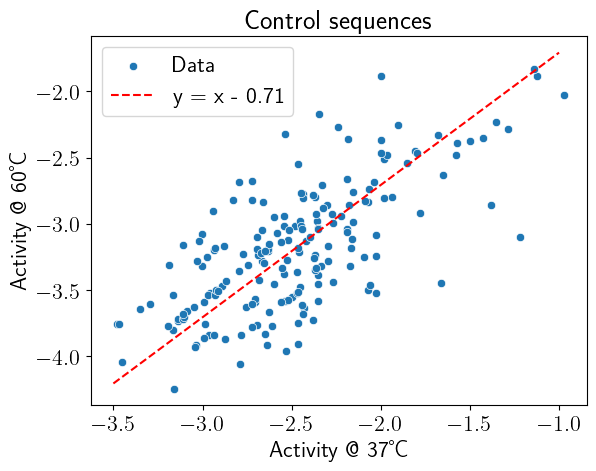

In [126]:
fig, ax = plt.subplots(dpi=100)
sns.scatterplot(
    df_control_f,
    x="activity_37",
    y="activity_60",
    ax=ax,
)

# linear fit
x = np.linspace(-3.5, -1.0, 100)
y = x * 1.0 + intercept
sns.lineplot(x=x, y=y, c="red", ls="--", ax=ax)
# ax.annotate(
#     f"r = {r_value:.2f}",
#     (-3.5, -2.0),
#     bbox=dict(
#         boxstyle="round4, pad=0.5",
#         lw=1,
#         fc="white",
#     )
# )

ax.legend(labels=["Data", f"y = x - {abs(intercept):.2f}"])
plt.title("Control sequences")
plt.xlabel("Activity @ 37℃")
plt.ylabel("Activity @ 60℃")

In [127]:
df_control_f["activity_37_mapped"] = df_control_f["activity_37"].to_numpy() + intercept

/var/folders/r7/6v5_mzt97glb0kxr73vgmbs00000gn/T/ipykernel_4473/2859114837.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_control_f["activity_37_mapped"] = df_control_f["activity_37"].to_numpy() + intercept


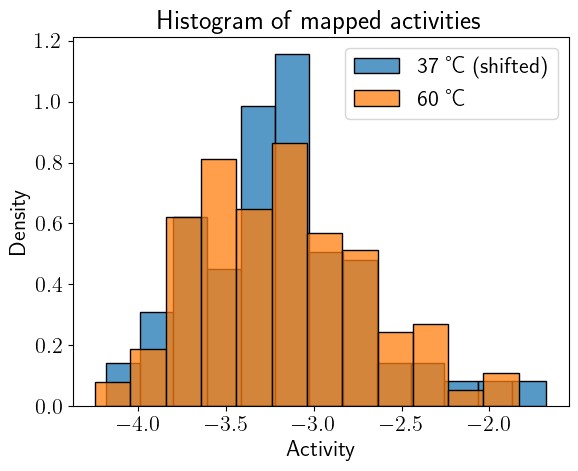

In [129]:
fig = plt.figure(dpi=100)
sns.histplot(
    df_control_f,
    x="activity_37_mapped",
    stat="density",
    binwidth=0.2,
)
sns.histplot(
    df_control_f,
    x="activity_60",
    stat="density",
    binwidth=0.2,
)
plt.title("Histogram of mapped activities")
plt.xlabel("Activity")
plt.legend(labels=["37 ℃ (shifted)", "60 ℃"])
plt.show()

In [130]:
activity_th = np.max(df_control_f["activity_37_mapped"].to_numpy())
print("Activity threshold (max of mapped 37 ℃):", activity_th)

Activity threshold (max of mapped 37 ℃): -1.677296157269379


## Compare results

In [131]:
df_data = df[df["region"] != "control"]
df_data["activity_37_mapped"] = df_data["activity_37"].to_numpy() + intercept
print(len(df_data))

2500


/var/folders/r7/6v5_mzt97glb0kxr73vgmbs00000gn/T/ipykernel_4473/4205924577.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_data["activity_37_mapped"] = df_data["activity_37"].to_numpy() + intercept


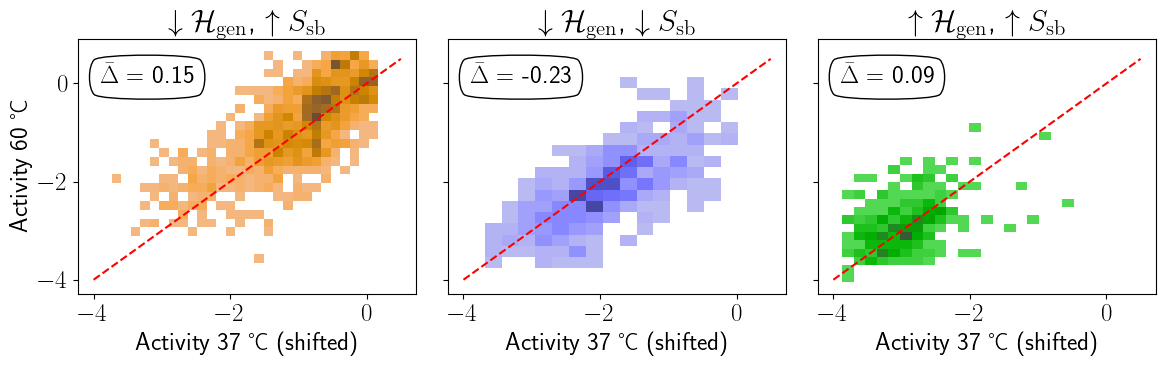

In [147]:
df_data_sel = df_data[
    (df_data["activity_37_mapped"] > -4.5) & (df_data["activity_60"] > -4.5)
]

title_map = {
    "highDCA_highSB": r"$\uparrow \mathcal{H}_{\mathrm{gen}}$, $\uparrow S_{\mathrm{sb}}$",
    "lowDCA_lowSB": r"$\downarrow \mathcal{H}_{\mathrm{gen}}$, $\downarrow S_{\mathrm{sb}}$",
    "lowDCA_highSB": r"$\downarrow \mathcal{H}_{\mathrm{gen}}$, $\uparrow S_{\mathrm{sb}}$",
}
colors = {
    "highDCA_highSB": "green",
    "lowDCA_lowSB": "blue",
    "lowDCA_highSB": "orange",
}

fig, ax = plt.subplots(1, 3, dpi=100, figsize=(12, 4), sharey=True)
for i, region in enumerate(["lowDCA_highSB", "lowDCA_lowSB", "highDCA_highSB"]):
    xmin, xmax = -4, 0.5
    df_plot = df_data_sel[df_data_sel["region"] == region]
    mean_delta_act = np.mean(- df_plot["activity_37_mapped"] + df_plot["activity_60"])
    sns.histplot(
        df_plot,
        x="activity_37_mapped",
        y="activity_60",
        ax=ax[i],
        color=colors[region],
    )
    x = np.linspace(xmin, xmax)
    sns.lineplot(
        x=x,
        y=x,
        c="red",
        ls="--",
        ax=ax[i]
    )
    ax[i].annotate(
        r"$\bar\Delta=$" + f" {mean_delta_act:.2f}",
        (-3.9, 0.0),
        bbox=dict(
            boxstyle="round4, pad=0.5",
            lw=1,
            fc="white",
        )
    )
    ax[i].set_title(title_map[region])
    ax[i].set_xlabel("Activity 37 ℃ (shifted)")
    #ax[i].set_xlim(xmin, xmax)
ax[0].set_ylabel("Activity 60 ℃")
plt.tight_layout()
plt.show()

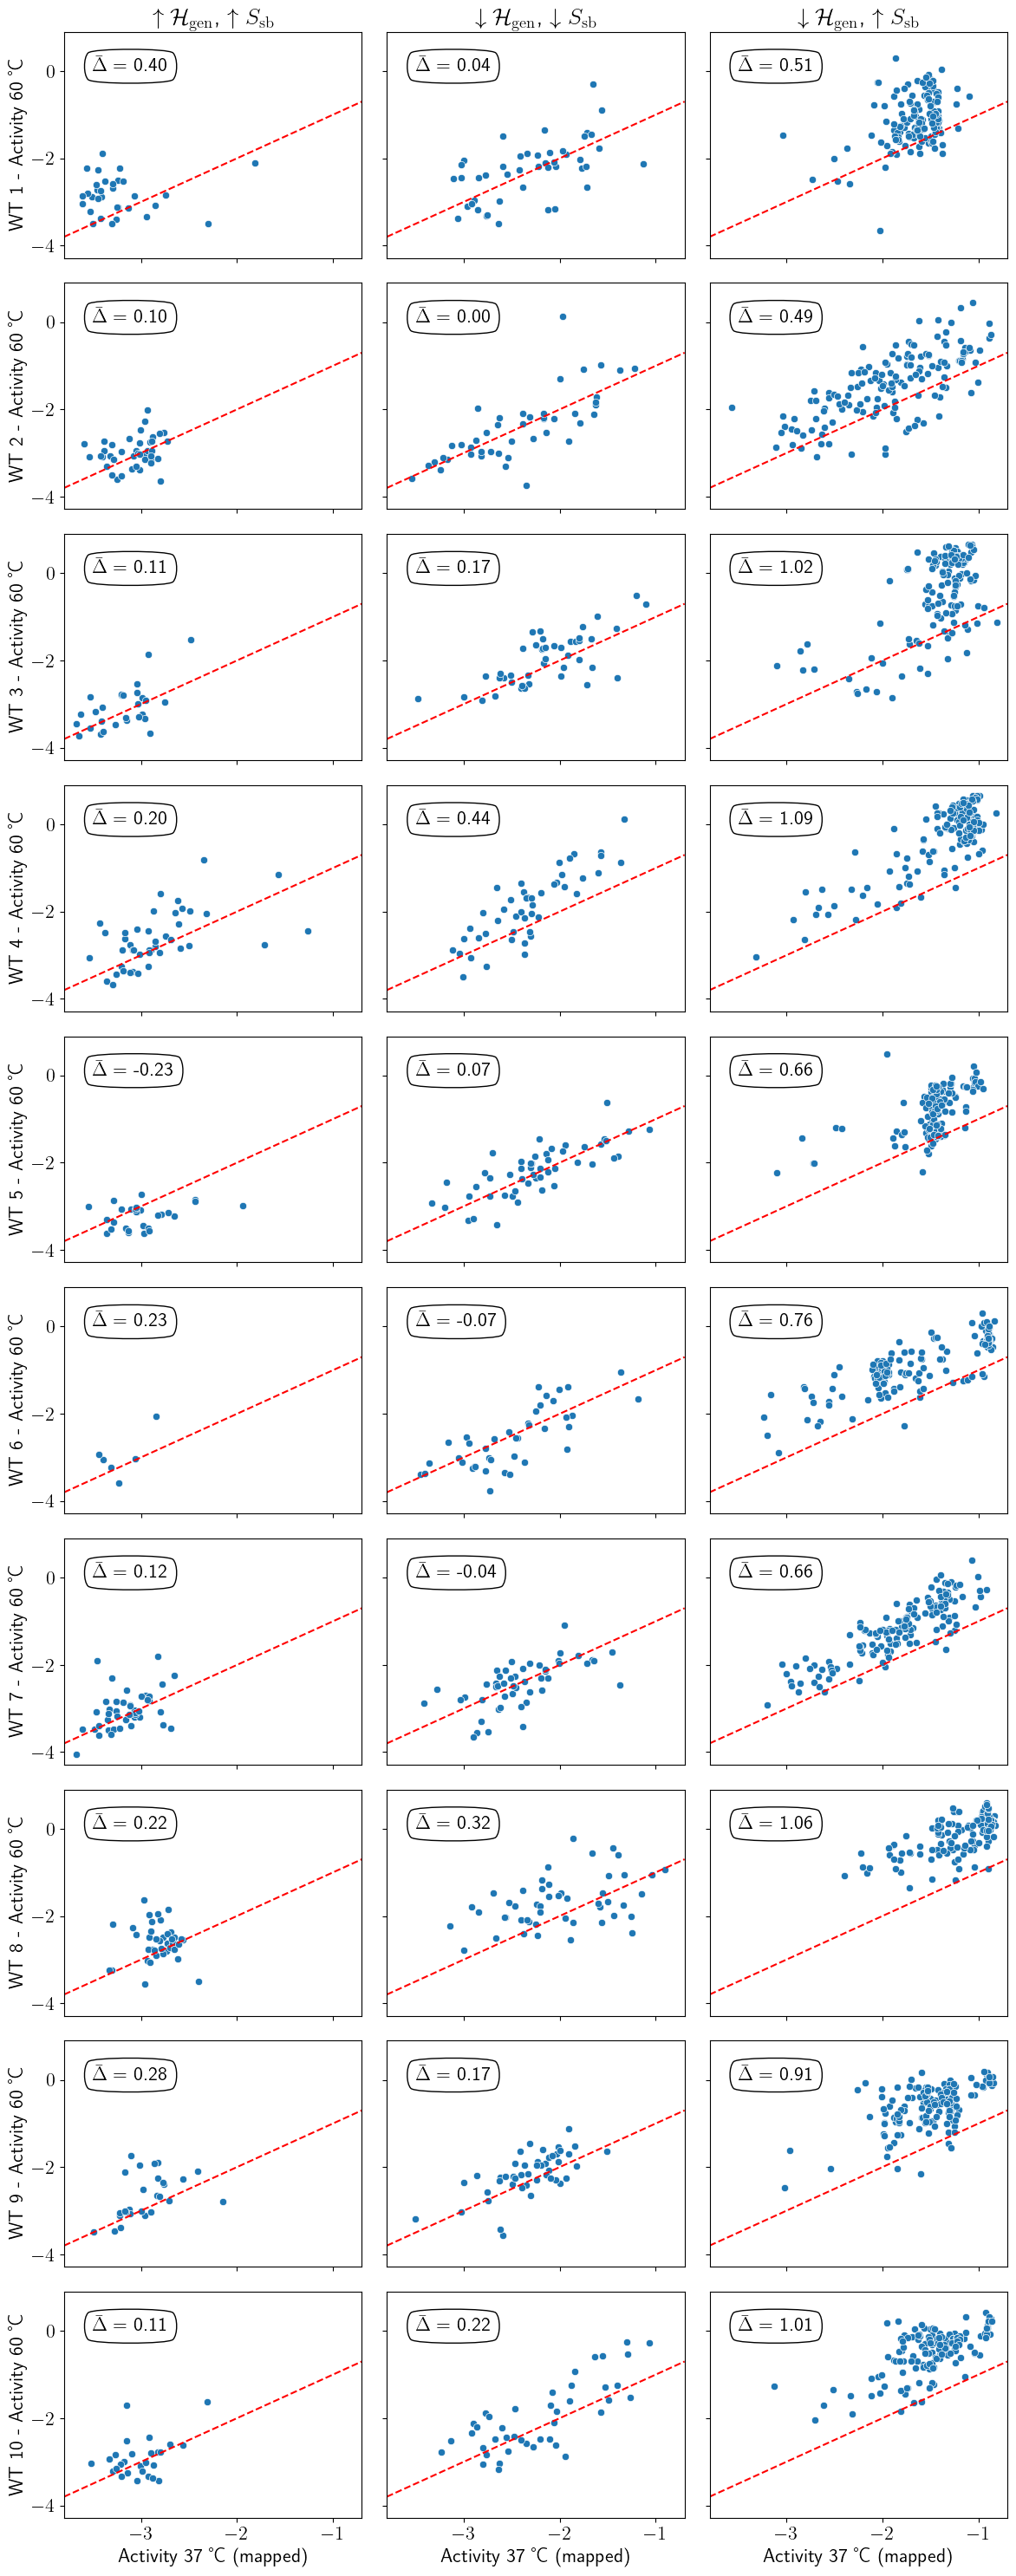

In [85]:
df_data_sel = df_data[
    (df_data["activity_37_mapped"] > -4.5) & (df_data["activity_60"] > -4.5)
]

title_map = {
    "highDCA_highSB": r"$\uparrow \mathcal{H}_{\mathrm{gen}}$, $\uparrow S_{\mathrm{sb}}$",
    "lowDCA_lowSB": r"$\downarrow \mathcal{H}_{\mathrm{gen}}$, $\downarrow S_{\mathrm{sb}}$",
    "lowDCA_highSB": r"$\downarrow \mathcal{H}_{\mathrm{gen}}$, $\uparrow S_{\mathrm{sb}}$",
}

fig, ax = plt.subplots(10, 3, dpi=100, figsize=(12, 30), sharey=True, sharex=True)
for wt_idx in range(1, 11):
    df_wt = df_data_sel[df_data_sel["wt_id"] == wt_idx]
    for i, region in enumerate(["highDCA_highSB", "lowDCA_lowSB", "lowDCA_highSB"]):
        xmin, xmax = -3.8, -0.7
        df_plot = df_wt[df_wt["region"] == region]
        mean_delta_act = np.mean(- df_plot["activity_37_mapped"] + df_plot["activity_60"])
        sns.scatterplot(
            df_plot,
            x="activity_37_mapped",
            y="activity_60",
            ax=ax[wt_idx-1, i]
        )
        x = np.linspace(xmin, xmax)
        sns.lineplot(
            x=x,
            y=x,
            c="red",
            ls="--",
            ax=ax[wt_idx-1, i]
        )
        ax[wt_idx-1, i].annotate(
            r"$\bar\Delta=$" + f" {mean_delta_act:.2f}",
            (-3.5, 0.0),
            bbox=dict(
                boxstyle="round4, pad=0.5",
                lw=1,
                fc="white",
            )
        )
    ax[wt_idx-1, 0].set_ylabel(f"WT {wt_idx} - Activity 60 ℃")
ax[0, 0].set_title(title_map["highDCA_highSB"])
ax[0, 1].set_title(title_map["lowDCA_lowSB"])
ax[0, 2].set_title(title_map["lowDCA_highSB"])
ax[9, 0].set_xlabel("Activity 37 ℃ (mapped)")
ax[9, 1].set_xlabel("Activity 37 ℃ (mapped)")
ax[9, 2].set_xlabel("Activity 37 ℃ (mapped)")
ax[9, 0].set_xlim(xmin, xmax)
ax[9, 1].set_xlim(xmin, xmax)
ax[9, 2].set_xlim(xmin, xmax)
plt.tight_layout()
plt.show()

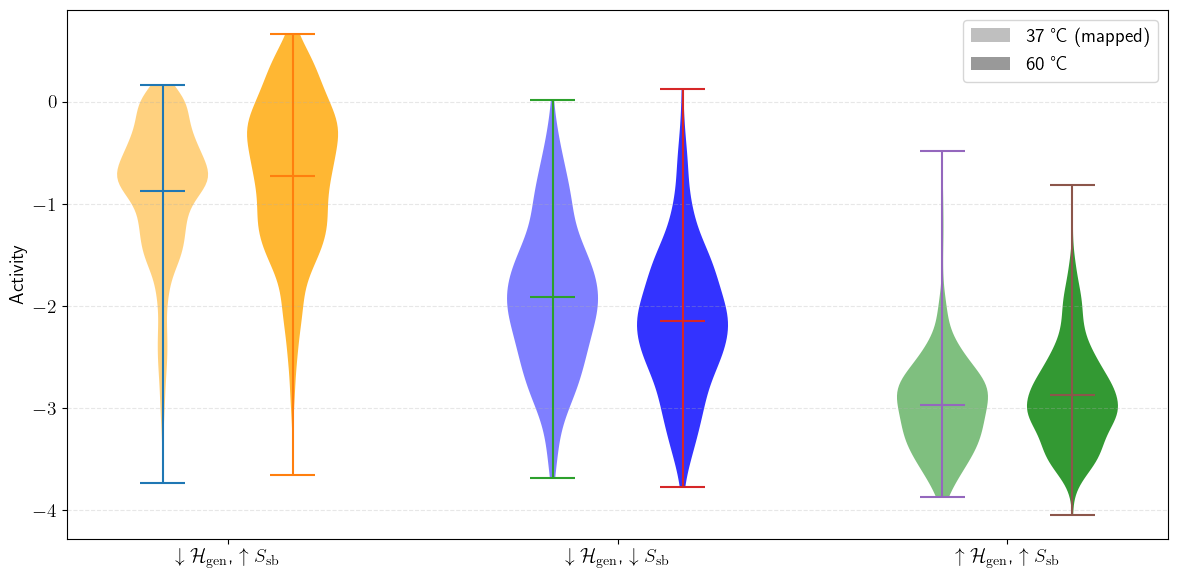

In [142]:
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.size": 14
    }
)

df_data_sel = df_data[
    (df_data["activity_37_mapped"] > -4.5) & (df_data["activity_60"] > -4.5)
]

title_map = {
    "highDCA_highSB": r"$\uparrow \mathcal{H}_{\mathrm{gen}}$, $\uparrow S_{\mathrm{sb}}$",
    "lowDCA_lowSB": r"$\downarrow \mathcal{H}_{\mathrm{gen}}$, $\downarrow S_{\mathrm{sb}}$",
    "lowDCA_highSB": r"$\downarrow \mathcal{H}_{\mathrm{gen}}$, $\uparrow S_{\mathrm{sb}}$",
}
colors = {
    "highDCA_highSB": "green",
    "lowDCA_lowSB": "blue",
    "lowDCA_highSB": "orange",
}

# Prepare data for violin plot
data_list = []
for region in ["lowDCA_highSB", "lowDCA_lowSB", "highDCA_highSB"]:
    df_region = df_data_sel[df_data_sel["region"] == region]
    
    # Add activity_37_mapped data
    for val in df_region["activity_37_mapped"]:
        data_list.append({
            "region": title_map[region],
            "temperature": "37 ℃",
            "activity": val,
            "color": colors[region]
        })
    
    # Add activity_60 data
    for val in df_region["activity_60"]:
        data_list.append({
            "region": title_map[region],
            "temperature": "60 ℃",
            "activity": val,
            "color": colors[region]
        })

df_violin = pd.DataFrame(data_list)

fig, ax = plt.subplots(dpi=100, figsize=(12, 6))

# Create violin plot
positions = []
violin_colors = []
for i, region in enumerate([r"$\downarrow \mathcal{H}_{\mathrm{gen}}$, $\uparrow S_{\mathrm{sb}}$",
                            r"$\downarrow \mathcal{H}_{\mathrm{gen}}$, $\downarrow S_{\mathrm{sb}}$",
                            r"$\uparrow \mathcal{H}_{\mathrm{gen}}$, $\uparrow S_{\mathrm{sb}}$"]):
    df_region = df_violin[df_violin["region"] == region]
    
    data_37 = df_region[df_region["temperature"] == "37 ℃"]["activity"].values
    data_60 = df_region[df_region["temperature"] == "60 ℃"]["activity"].values
    
    pos_37 = i * 3
    pos_60 = i * 3 + 1
    
    parts_37 = ax.violinplot([data_37], positions=[pos_37], widths=0.7, showmeans=True)
    parts_60 = ax.violinplot([data_60], positions=[pos_60], widths=0.7, showmeans=True)
    
    region_color = df_region["color"].iloc[0]
    
    for pc in parts_37['bodies']:
        pc.set_facecolor(region_color)
        pc.set_alpha(0.5)
    for pc in parts_60['bodies']:
        pc.set_facecolor(region_color)
        pc.set_alpha(0.8)
    
    positions.extend([pos_37, pos_60])

ax.set_xticks([0.5, 3.5, 6.5])
ax.set_xticklabels([r"$\downarrow \mathcal{H}_{\mathrm{gen}}$, $\uparrow S_{\mathrm{sb}}$",
                     r"$\downarrow \mathcal{H}_{\mathrm{gen}}$, $\downarrow S_{\mathrm{sb}}$",
                     r"$\uparrow \mathcal{H}_{\mathrm{gen}}$, $\uparrow S_{\mathrm{sb}}$"])
ax.set_ylabel("Activity")
ax.grid(axis='y', alpha=0.3, linestyle='--')

# Create legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='gray', alpha=0.5, label='37 ℃ (mapped)'),
                   Patch(facecolor='gray', alpha=0.8, label='60 ℃')]
ax.legend(handles=legend_elements, loc='upper right')

plt.tight_layout()
plt.show()

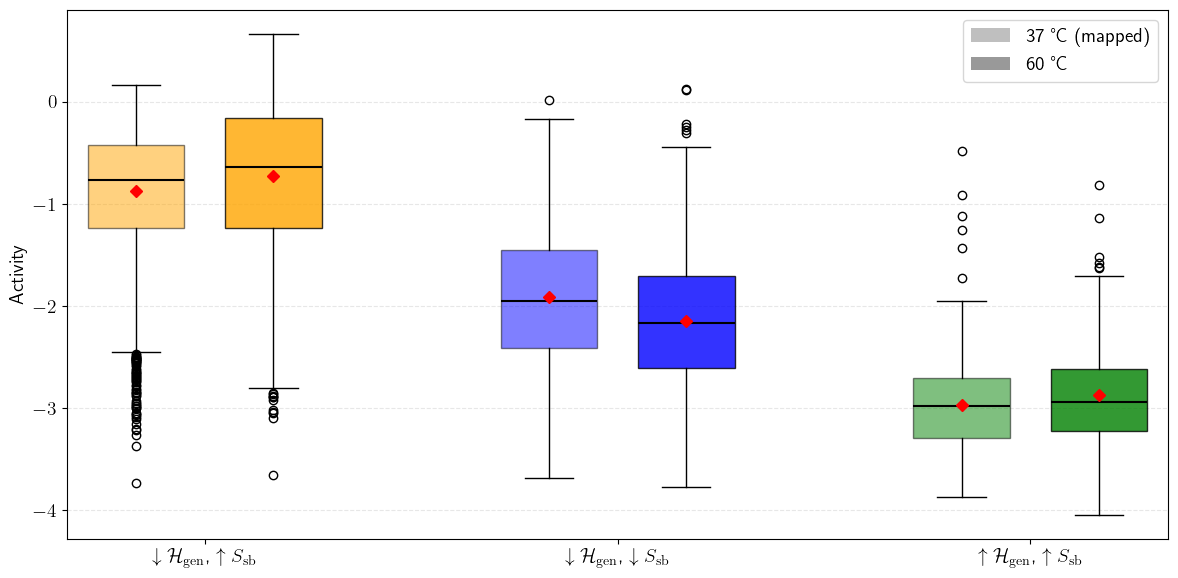

In [143]:
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.size": 14
    }
)

df_data_sel = df_data[
    (df_data["activity_37_mapped"] > -4.5) & (df_data["activity_60"] > -4.5)
]

title_map = {
    "highDCA_highSB": r"$\uparrow \mathcal{H}_{\mathrm{gen}}$, $\uparrow S_{\mathrm{sb}}$",
    "lowDCA_lowSB": r"$\downarrow \mathcal{H}_{\mathrm{gen}}$, $\downarrow S_{\mathrm{sb}}$",
    "lowDCA_highSB": r"$\downarrow \mathcal{H}_{\mathrm{gen}}$, $\uparrow S_{\mathrm{sb}}$",
}
colors = {
    "highDCA_highSB": "green",
    "lowDCA_lowSB": "blue",
    "lowDCA_highSB": "orange",
}

# Prepare data for boxplot
data_list = []
for region in ["lowDCA_highSB", "lowDCA_lowSB", "highDCA_highSB"]:
    df_region = df_data_sel[df_data_sel["region"] == region]
    
    # Add activity_37_mapped data
    for val in df_region["activity_37_mapped"]:
        data_list.append({
            "region": title_map[region],
            "temperature": "37 ℃",
            "activity": val,
            "color": colors[region]
        })
    
    # Add activity_60 data
    for val in df_region["activity_60"]:
        data_list.append({
            "region": title_map[region],
            "temperature": "60 ℃",
            "activity": val,
            "color": colors[region]
        })

df_boxplot = pd.DataFrame(data_list)

fig, ax = plt.subplots(dpi=100, figsize=(12, 6))

# Create boxplot
positions = []
for i, region in enumerate([r"$\downarrow \mathcal{H}_{\mathrm{gen}}$, $\uparrow S_{\mathrm{sb}}$",
                            r"$\downarrow \mathcal{H}_{\mathrm{gen}}$, $\downarrow S_{\mathrm{sb}}$",
                            r"$\uparrow \mathcal{H}_{\mathrm{gen}}$, $\uparrow S_{\mathrm{sb}}$"]):
    df_region = df_boxplot[df_boxplot["region"] == region]
    
    data_37 = df_region[df_region["temperature"] == "37 ℃"]["activity"].values
    data_60 = df_region[df_region["temperature"] == "60 ℃"]["activity"].values
    
    pos_37 = i * 3
    pos_60 = i * 3 + 1
    
    region_color = df_region["color"].iloc[0]
    
    bp1 = ax.boxplot([data_37], positions=[pos_37], widths=0.7, 
                      patch_artist=True, showmeans=True,
                      boxprops=dict(facecolor=region_color, alpha=0.5),
                      medianprops=dict(color='black', linewidth=1.5),
                      meanprops=dict(marker='D', markerfacecolor='red', markeredgecolor='red'))
    
    bp2 = ax.boxplot([data_60], positions=[pos_60], widths=0.7,
                      patch_artist=True, showmeans=True,
                      boxprops=dict(facecolor=region_color, alpha=0.8),
                      medianprops=dict(color='black', linewidth=1.5),
                      meanprops=dict(marker='D', markerfacecolor='red', markeredgecolor='red'))
    
    positions.extend([pos_37, pos_60])

ax.set_xticks([0.5, 3.5, 6.5])
ax.set_xticklabels([r"$\downarrow \mathcal{H}_{\mathrm{gen}}$, $\uparrow S_{\mathrm{sb}}$",
                     r"$\downarrow \mathcal{H}_{\mathrm{gen}}$, $\downarrow S_{\mathrm{sb}}$",
                     r"$\uparrow \mathcal{H}_{\mathrm{gen}}$, $\uparrow S_{\mathrm{sb}}$"])
ax.set_ylabel("Activity")
ax.grid(axis='y', alpha=0.3, linestyle='--')

# Create legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='gray', alpha=0.5, label='37 ℃ (mapped)'),
                   Patch(facecolor='gray', alpha=0.8, label='60 ℃')]
ax.legend(handles=legend_elements, loc='upper right')

plt.tight_layout()
plt.show()

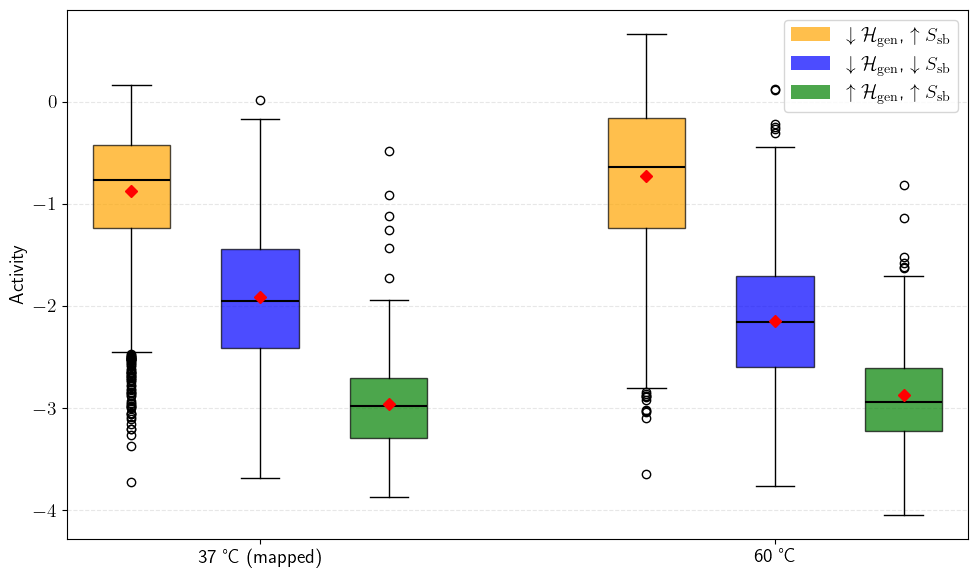

In [144]:
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.size": 14
    }
)

df_data_sel = df_data[
    (df_data["activity_37_mapped"] > -4.5) & (df_data["activity_60"] > -4.5)
]

title_map = {
    "highDCA_highSB": r"$\uparrow \mathcal{H}_{\mathrm{gen}}$, $\uparrow S_{\mathrm{sb}}$",
    "lowDCA_lowSB": r"$\downarrow \mathcal{H}_{\mathrm{gen}}$, $\downarrow S_{\mathrm{sb}}$",
    "lowDCA_highSB": r"$\downarrow \mathcal{H}_{\mathrm{gen}}$, $\uparrow S_{\mathrm{sb}}$",
}
colors = {
    "highDCA_highSB": "green",
    "lowDCA_lowSB": "blue",
    "lowDCA_highSB": "orange",
}

fig, ax = plt.subplots(dpi=100, figsize=(10, 6))

# Create boxplot grouped by temperature
positions_37 = [1, 2, 3]
positions_60 = [5, 6, 7]

for i, region in enumerate(["lowDCA_highSB", "lowDCA_lowSB", "highDCA_highSB"]):
    df_region = df_data_sel[df_data_sel["region"] == region]
    
    data_37 = df_region["activity_37_mapped"].values
    data_60 = df_region["activity_60"].values
    
    region_color = colors[region]
    
    # Boxplot for 37°C
    bp1 = ax.boxplot([data_37], positions=[positions_37[i]], widths=0.6,
                      patch_artist=True, showmeans=True,
                      boxprops=dict(facecolor=region_color, alpha=0.7),
                      medianprops=dict(color='black', linewidth=1.5),
                      meanprops=dict(marker='D', markerfacecolor='red', markeredgecolor='red'))
    
    # Boxplot for 60°C
    bp2 = ax.boxplot([data_60], positions=[positions_60[i]], widths=0.6,
                      patch_artist=True, showmeans=True,
                      boxprops=dict(facecolor=region_color, alpha=0.7),
                      medianprops=dict(color='black', linewidth=1.5),
                      meanprops=dict(marker='D', markerfacecolor='red', markeredgecolor='red'))

ax.set_xticks([2, 6])
ax.set_xticklabels(['37 ℃ (mapped)', '60 ℃'])
ax.set_ylabel("Activity")
ax.grid(axis='y', alpha=0.3, linestyle='--')

# Create legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='orange', alpha=0.7, label=r"$\downarrow \mathcal{H}_{\mathrm{gen}}$, $\uparrow S_{\mathrm{sb}}$"),
    Patch(facecolor='blue', alpha=0.7, label=r"$\downarrow \mathcal{H}_{\mathrm{gen}}$, $\downarrow S_{\mathrm{sb}}$"),
    Patch(facecolor='green', alpha=0.7, label=r"$\uparrow \mathcal{H}_{\mathrm{gen}}$, $\uparrow S_{\mathrm{sb}}$")
]
ax.legend(handles=legend_elements, loc='upper right')

plt.tight_layout()
plt.show()

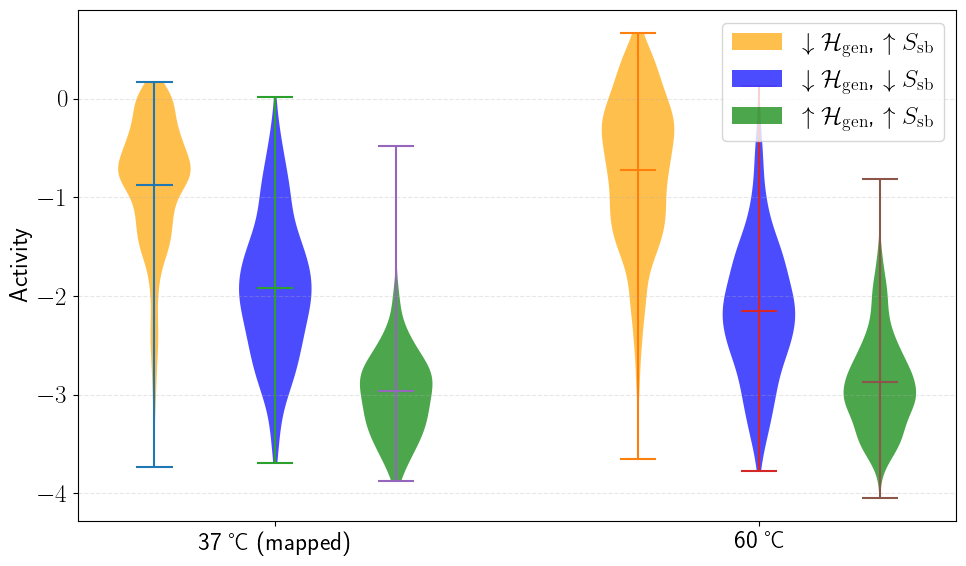

In [146]:
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.size": 18
    }
)

df_data_sel = df_data[
    (df_data["activity_37_mapped"] > -4.5) & (df_data["activity_60"] > -4.5)
]

title_map = {
    "highDCA_highSB": r"$\uparrow \mathcal{H}_{\mathrm{gen}}$, $\uparrow S_{\mathrm{sb}}$",
    "lowDCA_lowSB": r"$\downarrow \mathcal{H}_{\mathrm{gen}}$, $\downarrow S_{\mathrm{sb}}$",
    "lowDCA_highSB": r"$\downarrow \mathcal{H}_{\mathrm{gen}}$, $\uparrow S_{\mathrm{sb}}$",
}
colors = {
    "highDCA_highSB": "green",
    "lowDCA_lowSB": "blue",
    "lowDCA_highSB": "orange",
}

fig, ax = plt.subplots(dpi=100, figsize=(10, 6))

# Create violin plot grouped by temperature
positions_37 = [1, 2, 3]
positions_60 = [5, 6, 7]

for i, region in enumerate(["lowDCA_highSB", "lowDCA_lowSB", "highDCA_highSB"]):
    df_region = df_data_sel[df_data_sel["region"] == region]
    
    data_37 = df_region["activity_37_mapped"].values
    data_60 = df_region["activity_60"].values
    
    region_color = colors[region]
    
    # Violin plot for 37°C
    parts_37 = ax.violinplot([data_37], positions=[positions_37[i]], widths=0.6, showmeans=True)
    for pc in parts_37['bodies']:
        pc.set_facecolor(region_color)
        pc.set_alpha(0.7)
    
    # Violin plot for 60°C
    parts_60 = ax.violinplot([data_60], positions=[positions_60[i]], widths=0.6, showmeans=True)
    for pc in parts_60['bodies']:
        pc.set_facecolor(region_color)
        pc.set_alpha(0.7)

ax.set_xticks([2, 6])
ax.set_xticklabels(['37 ℃ (mapped)', '60 ℃'])
ax.set_ylabel("Activity")
ax.grid(axis='y', alpha=0.3, linestyle='--')

# Create legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='orange', alpha=0.7, label=r"$\downarrow \mathcal{H}_{\mathrm{gen}}$, $\uparrow S_{\mathrm{sb}}$"),
    Patch(facecolor='blue', alpha=0.7, label=r"$\downarrow \mathcal{H}_{\mathrm{gen}}$, $\downarrow S_{\mathrm{sb}}$"),
    Patch(facecolor='green', alpha=0.7, label=r"$\uparrow \mathcal{H}_{\mathrm{gen}}$, $\uparrow S_{\mathrm{sb}}$")
]
ax.legend(handles=legend_elements, loc='upper right')

plt.tight_layout()
plt.show()

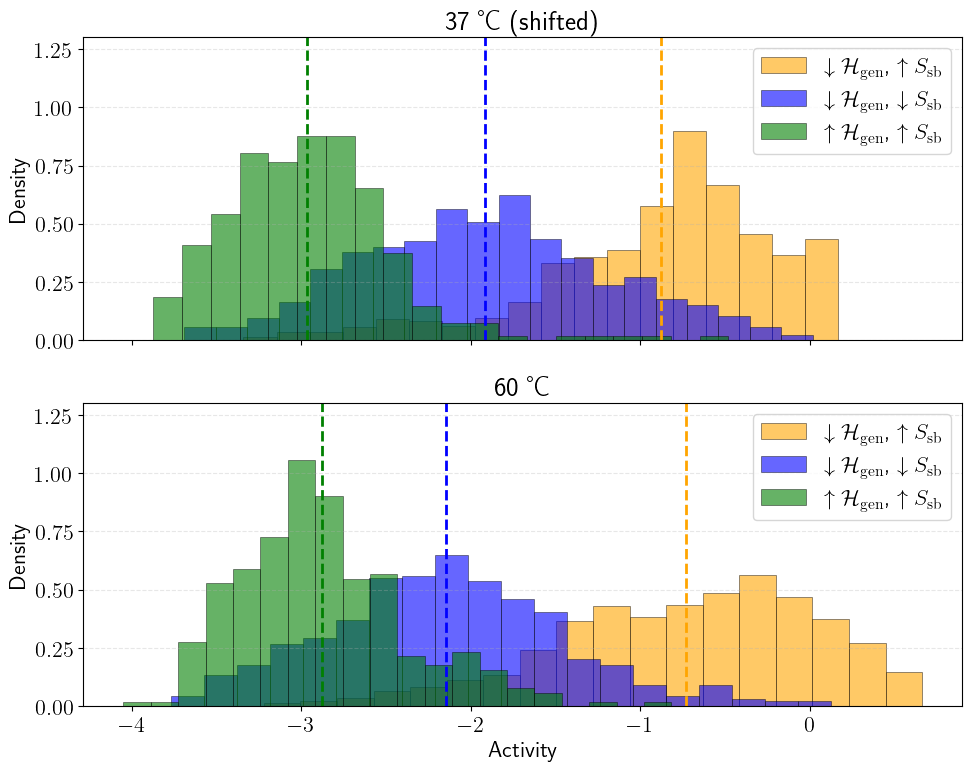

In [152]:
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.size": 16
    }
)

df_data_sel = df_data[
    (df_data["activity_37_mapped"] > -4.5) & (df_data["activity_60"] > -4.5)
]

title_map = {
    "highDCA_highSB": r"$\uparrow \mathcal{H}_{\mathrm{gen}}$, $\uparrow S_{\mathrm{sb}}$",
    "lowDCA_lowSB": r"$\downarrow \mathcal{H}_{\mathrm{gen}}$, $\downarrow S_{\mathrm{sb}}$",
    "lowDCA_highSB": r"$\downarrow \mathcal{H}_{\mathrm{gen}}$, $\uparrow S_{\mathrm{sb}}$",
}
colors = {
    "highDCA_highSB": "green",
    "lowDCA_lowSB": "blue",
    "lowDCA_highSB": "orange",
}

fig, (ax1, ax2) = plt.subplots(2, 1, dpi=100, figsize=(10, 8), sharex=True)

# Upper plot: 37°C (mapped)
for region in ["lowDCA_highSB", "lowDCA_lowSB", "highDCA_highSB"]:
    df_region = df_data_sel[df_data_sel["region"] == region]
    data_37 = df_region["activity_37_mapped"].values
    mean_37 = np.mean(data_37)
    
    ax1.hist(data_37, bins=20, alpha=0.6, color=colors[region], 
             label=title_map[region], edgecolor='black', linewidth=0.5, density=True)
    ax1.axvline(mean_37, color=colors[region], linestyle='--', linewidth=2)

ax1.set_ylabel("Density")
ax1.set_title("37 ℃ (shifted)")
ax1.legend(loc='upper right')
ax1.grid(axis='y', alpha=0.3, linestyle='--')
ax1.set_ylim(0, 1.3)

# Lower plot: 60°C
for region in ["lowDCA_highSB", "lowDCA_lowSB", "highDCA_highSB"]:
    df_region = df_data_sel[df_data_sel["region"] == region]
    data_60 = df_region["activity_60"].values
    mean_60 = np.mean(data_60)
    
    ax2.hist(data_60, bins=20, alpha=0.6, color=colors[region], 
             label=title_map[region], edgecolor='black', linewidth=0.5, density=True)
    ax2.axvline(mean_60, color=colors[region], linestyle='--', linewidth=2)

ax2.set_ylabel("Density")
ax2.set_xlabel("Activity")
ax2.set_title("60 ℃")
ax2.legend(loc='upper right')
ax2.grid(axis='y', alpha=0.3, linestyle='--')
ax2.set_ylim(0, 1.3)
plt.tight_layout()
plt.show()

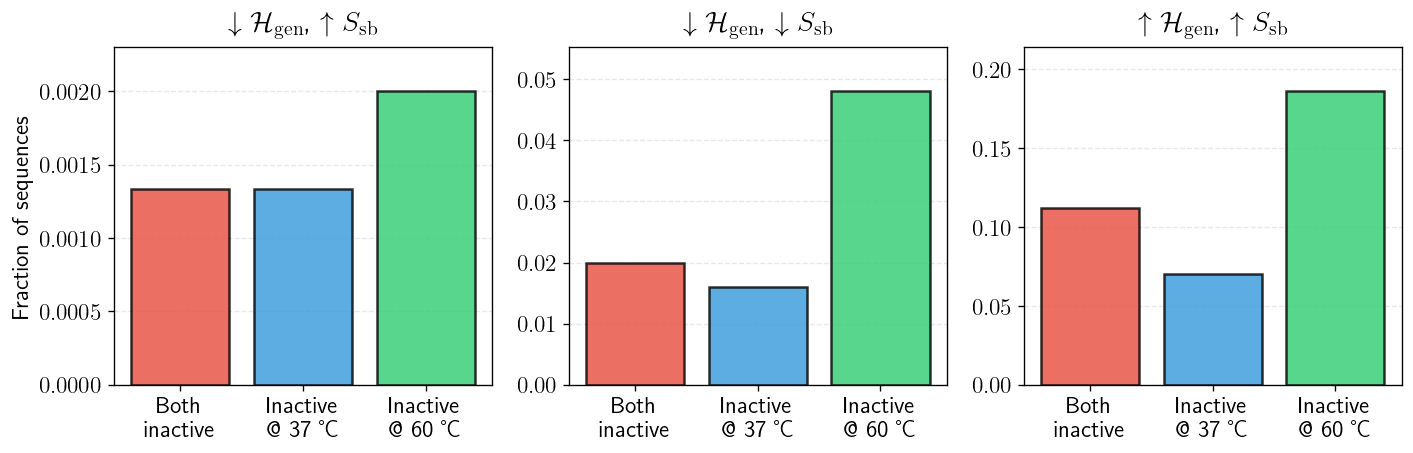

In [148]:
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.size": 14
    }
)

df_data_inactive = df_data[
    (df_data["activity_37_mapped"] < -4.5) | (df_data["activity_60"] < -4.5)
]

fig, ax = plt.subplots(1, 3, dpi=120, figsize=(12, 4.0), sharey=False)
colors = ['#e74c3c', '#3498db', '#2ecc71']

for i, region in enumerate(["lowDCA_highSB", "lowDCA_lowSB", "highDCA_highSB"]):
    df_region = df_data_inactive[df_data_inactive["region"] == region]
    n_tot_region = len(df_data[df_data["region"] == region])
    
    inactive_fraction = df_region[(df_region["activity_37_mapped"] < -4.5) & (df_region["activity_60"] < -4.5)].shape[0] / n_tot_region
    inactive_37_active_60 = df_region[(df_region["activity_37_mapped"] < -4.5) & (df_region["activity_60"] > -4.5)].shape[0] / n_tot_region
    active_37_inactive_60 = df_region[(df_region["activity_37_mapped"] > -4.5) & (df_region["activity_60"] < -4.5)].shape[0] / n_tot_region
    
    categories = ['Both\ninactive', 'Inactive\n@ 37 ℃', 'Inactive\n@ 60 ℃']
    values = [inactive_fraction, inactive_37_active_60, active_37_inactive_60]
    
    bars = ax[i].bar(categories, values, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)
    
    ax[i].set_title(title_map[region], pad=10)
    ax[i].set_ylim(0, max(values) * 1.15)
    ax[i].grid(axis='y', alpha=0.3, linestyle='--')
    ax[i].set_axisbelow(True)
    ax[i].tick_params(axis='x')
    ax[i].tick_params(axis='y')

ax[0].set_ylabel("Fraction of sequences")
plt.tight_layout()
plt.show()